# MedTwin AI — Phase 3: Tumor Localization & Volume Measurement (Inference)

**Project:** MedTwin AI — AI-Based Multi-Disease Brain MRI 3D Reconstruction and Volumetry

**Phase 3 objective:** use the **trained Phase 2 model** to run inference on a brain MRI, then
**localize** and **measure the volume** of the predicted tumor sub-regions.

Pipeline covered here: **MRI → preprocessing → trained-model segmentation → localization →
volume/size measurement → structured report.**

This notebook does **not**:
- Retrain or fine-tune the model (it loads the Phase 2 checkpoint as-is).
- Build the 3D mesh reconstruction or interactive viewer (Phase 4).
- Generate a clinical report narrative (a later phase).
- Make any clinical or diagnostic claim — this is a research prototype.

**Assumption:** since a specific Phase 3 spec wasn't given, this notebook follows the phase order
from your original project goal (segmentation → localization → volume measurement → 3D
reconstruction → viewer → report). If you meant something different by "next phase," let me know
and I'll adjust.

It supports two modes, set in Cell 2:
- **`test_patient`** — run on a held-out Phase 2 test-set patient (ground truth available, so we
  can also report Dice/IoU as a sanity check that the loaded model matches training results).
- **`new_patient`** — run on any new MRI folder with T1/T1c/T2/FLAIR files (no ground truth).


## Cell 1 — Environment Verification & Device Selection


In [1]:
import sys
import importlib
from importlib.metadata import version as pkg_version, PackageNotFoundError

def check_environment():
    required = ["torch", "monai", "numpy", "nibabel", "pandas"]
    rows = [("python", sys.version.split()[0], "Available")]
    for name in required:
        try:
            module = importlib.import_module(name)
            try:
                ver = pkg_version(name)
            except PackageNotFoundError:
                ver = getattr(module, "__version__", "unknown")
            rows.append((name, ver, "Available"))
        except ImportError:
            rows.append((name, "-", "Missing"))

    name_w = max(len(r[0]) for r in rows) + 2
    ver_w = max(len(str(r[1])) for r in rows) + 2
    print("Environment Check")
    print("-" * (name_w + ver_w + 12))
    for name, ver, status in rows:
        print(f"{name:<{name_w}}{str(ver):<{ver_w}}{status}")

    missing = [r[0] for r in rows if r[2] == "Missing"]
    if missing:
        print("\nMissing packages:", ", ".join(missing))
        print("Install with: pip install " + " ".join(missing))
    else:
        print("\nAll required packages are available.")

check_environment()


Environment Check
-----------------------------------
python   3.11.15       Available
torch    2.11.0+cu128  Available
monai    1.6.0         Available
numpy    2.4.6         Available
nibabel  5.4.2         Available
pandas   3.0.5         Available

All required packages are available.


In [2]:
import torch

def select_device():
    if torch.cuda.is_available():
        device = torch.device("cuda")
        print(f"CUDA available — using GPU: {torch.cuda.get_device_name(0)}")
    else:
        device = torch.device("cpu")
        print("CUDA not available — using CPU.")
    return device

DEVICE = select_device()
print(f"\nSelected device: {DEVICE}")


CUDA available — using GPU: NVIDIA GeForce RTX 5050 Laptop GPU

Selected device: cuda


In [3]:
import pandas as pd
import json

print(f"pandas version: {pd.__version__}")


pandas version: 3.0.5


## Cell 2 — Paths and Inference Mode

`MODEL_BUNDLE_PATH` should point at the `model_bundle.json` saved by Phase 2 (Cell 22). It carries
the model architecture, label mapping, preprocessing settings, and the train/val/test patient split
— so this notebook rebuilds the exact pipeline Phase 2 trained with, rather than re-typing settings
that could drift out of sync.

Set `INFERENCE_MODE`:
- `"test_patient"` — pick a patient from the Phase 2 **test** split (never used in training/model
  selection) so ground truth is available for a sanity-check comparison.
- `"new_patient"` — point `NEW_PATIENT_DIR` at a folder containing that patient's T1/T1c/T2/FLAIR
  NIfTI files (no ground truth required).


In [4]:
from pathlib import Path

# ----- EDIT THESE -----
OUTPUT_DIR = Path(r"C:\Users\shshi\Downloads\Med_Twin\outputs")
MODEL_BUNDLE_PATH = OUTPUT_DIR / "model_bundle" / "model_bundle.json"

INFERENCE_MODE = "test_patient"  # "test_patient" or "new_patient"

# Used only if INFERENCE_MODE == "test_patient": which patient from the saved test split to use.
# None -> automatically use the first test-split patient found on disk.
TEST_PATIENT_ID = None

# Used only if INFERENCE_MODE == "new_patient": folder containing that patient's modality files.
NEW_PATIENT_DIR = Path(r"C:\Users\admin\Desktop\Med_Twin\Dataset\NewPatient001")
# ------------------------

REPORT_DIR = OUTPUT_DIR / "phase3_reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print(f"OUTPUT_DIR:         {OUTPUT_DIR}")
print(f"MODEL_BUNDLE_PATH:  {MODEL_BUNDLE_PATH}")
print(f"INFERENCE_MODE:     {INFERENCE_MODE}")
print(f"REPORT_DIR:         {REPORT_DIR}")

if not MODEL_BUNDLE_PATH.exists():
    print(
        f"\nWARNING: model bundle not found at {MODEL_BUNDLE_PATH}\n"
        "Run Phase 2 through Cell 22 (Save Model and Configuration) first, or update this path."
    )


OUTPUT_DIR:         C:\Users\shshi\Downloads\Med_Twin\outputs
MODEL_BUNDLE_PATH:  C:\Users\shshi\Downloads\Med_Twin\outputs\model_bundle\model_bundle.json
INFERENCE_MODE:     test_patient
REPORT_DIR:         C:\Users\shshi\Downloads\Med_Twin\outputs\phase3_reports


## Cell 3 — Load the Model Bundle

Load the JSON saved by Phase 2: model architecture, label mapping, preprocessing configuration, and
split information. Everything below is driven by these values, not re-typed.


In [5]:
def load_model_bundle(path: Path):
    if not path.exists():
        print(f"Model bundle not found: {path}")
        return None
    with open(path, "r") as f:
        bundle = json.load(f)
    return bundle

model_bundle = load_model_bundle(MODEL_BUNDLE_PATH)

if model_bundle is not None:
    print("Loaded model bundle")
    print("-" * 40)
    print(f"Checkpoint path:      {model_bundle['checkpoint_path']}")
    print(f"Model architecture:   {model_bundle['model_config']['architecture']}")
    print(f"Input modalities:     {model_bundle['model_config']['modality_order']}")
    print(f"Label mapping:        {model_bundle['label_mapping']}")
    print(f"Target spacing (mm):  {model_bundle['preprocessing_config']['target_spacing_mm']}")
    print(f"Test-set patients:    {len(model_bundle['split_info']['test_patients'])}")
else:
    print("Cannot proceed without a model bundle — check MODEL_BUNDLE_PATH in Cell 2.")


Loaded model bundle
----------------------------------------
Checkpoint path:      C:\Users\shshi\Downloads\Med_Twin\outputs\checkpoints\best_model.pth
Model architecture:   MONAI 3D UNet
Input modalities:     ['t1', 't1c', 't2', 'flair']
Label mapping:        {'0': 'background', '1': 'necrotic_core', '2': 'edema', '3': 'enhancing_tumor'}
Target spacing (mm):  [1.0, 1.0, 1.0]
Test-set patients:    188


## Cell 4 — Rebuild Inference Preprocessing

Full-volume preprocessing (no random cropping, no augmentation) built from the bundle's saved
`preprocessing_config`, so inference uses exactly the same orientation/spacing/normalization/padding
convention the model was trained under.


In [6]:
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, Orientationd, Spacingd,
    NormalizeIntensityd, CropForegroundd, ConcatItemsd, DeleteItemsd, EnsureTyped, DivisiblePadd
)

# Same BraTS filename convention used in Phase 2. If your naming differs, update this dict.
MODALITY_FILENAME_SUFFIXES = {
    "t1": "-t1n.nii.gz",
    "t1c": "-t1c.nii.gz",
    "t2": "-t2w.nii.gz",
    "flair": "-t2f.nii.gz",
}
LABEL_FILENAME_SUFFIX = "-seg.nii.gz"

MODALITY_KEYS = model_bundle["model_config"]["modality_order"] if model_bundle else list(MODALITY_FILENAME_SUFFIXES)
LABEL_KEY = "seg"

def get_divisible_pad_factor(bundle):
    '''Older Phase 2 bundles (saved before patch-based training was introduced) don't have
    "divisible_pad_factor" in preprocessing_config. Fall back to computing it from the model's
    own strides, which is always present and gives the same value Phase 2 would have used.'''
    cfg = bundle["preprocessing_config"]
    if "divisible_pad_factor" in cfg:
        return cfg["divisible_pad_factor"]

    strides = bundle["model_config"].get("strides", [2, 2, 2])
    factor = 1
    for s in strides:
        factor *= s
    print(f"NOTE: 'divisible_pad_factor' not found in the saved bundle (older Phase 2 version) — "
          f"computed {factor} from model_config['strides']={strides} instead.")
    return factor

def build_inference_transforms(bundle):
    cfg = bundle["preprocessing_config"]
    all_keys = MODALITY_KEYS + [LABEL_KEY]

    target_orientation = cfg.get("target_orientation", "RAS")
    target_spacing_mm = cfg.get("target_spacing_mm", [1.0, 1.0, 1.0])
    divisible_pad_factor = get_divisible_pad_factor(bundle)

    return Compose([
        LoadImaged(keys=all_keys, image_only=True, allow_missing_keys=True),
        EnsureChannelFirstd(keys=all_keys, allow_missing_keys=True),
        Orientationd(keys=all_keys, axcodes=target_orientation, allow_missing_keys=True),
        Spacingd(
            keys=all_keys, pixdim=tuple(target_spacing_mm),
            mode=["bilinear"] * len(MODALITY_KEYS) + ["nearest"],
            allow_missing_keys=True,
        ),
        NormalizeIntensityd(keys=MODALITY_KEYS, nonzero=True, channel_wise=True),
        ConcatItemsd(keys=MODALITY_KEYS, name="image"),
        DeleteItemsd(keys=MODALITY_KEYS),
        CropForegroundd(keys=["image", LABEL_KEY], source_key="image", allow_missing_keys=True),
        DivisiblePadd(keys=["image", LABEL_KEY], k=divisible_pad_factor, allow_missing_keys=True),
        EnsureTyped(keys=["image", LABEL_KEY], allow_missing_keys=True, track_meta=True),
        # track_meta=True here (unlike Phase 2 training): we need the affine after preprocessing
        # to convert voxel measurements to physical mm in the localization/volume cells below.
    ])

inference_transforms = build_inference_transforms(model_bundle) if model_bundle else None
if inference_transforms is not None:
    print("Inference preprocessing pipeline created:")
    for t in inference_transforms.transforms:
        print(f"  - {type(t).__name__}")


NOTE: 'divisible_pad_factor' not found in the saved bundle (older Phase 2 version) — computed 8 from model_config['strides']=[2, 2, 2] instead.
Inference preprocessing pipeline created:
  - LoadImaged
  - EnsureChannelFirstd
  - Orientationd
  - Spacingd
  - NormalizeIntensityd
  - ConcatItemsd
  - DeleteItemsd
  - CropForegroundd
  - DivisiblePadd
  - EnsureTyped


C:\Users\shshi\anaconda3\envs\Med_twin\Lib\site-packages\monai\utils\deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


## Cell 5 — Rebuild Model Architecture and Load Trained Weights

Rebuild the exact 3D U-Net architecture from the bundle's `model_config`, then load the trained
weights (`best_model.pth`) with `strict=True` so any architecture/checkpoint mismatch fails loudly
instead of silently loading partial/wrong weights.


In [7]:
from monai.networks.nets import UNet
from monai.networks.layers import Norm

def build_model_from_config(model_config, device):
    model = UNet(
        spatial_dims=model_config["spatial_dims"],
        in_channels=model_config["in_channels"],
        out_channels=model_config["out_channels"],
        channels=tuple(model_config["channels"]),
        strides=tuple(model_config["strides"]),
        num_res_units=model_config["num_res_units"],
        norm=Norm.BATCH,
    ).to(device)
    return model

model = None
model_loaded_ok = False

if model_bundle is not None:
    model = build_model_from_config(model_bundle["model_config"], DEVICE)
    ckpt_path = Path(model_bundle["checkpoint_path"])

    if not ckpt_path.exists():
        print(f"Checkpoint file not found: {ckpt_path}")
        print("Train and save a model in Phase 2 first (Cells 18/22).")
    else:
        state_dict = torch.load(ckpt_path, map_location=DEVICE)
        model.load_state_dict(state_dict, strict=True)
        model.eval()
        model_loaded_ok = True

        n_params = sum(p.numel() for p in model.parameters())
        print("Model loaded successfully")
        print("-" * 40)
        print(f"Checkpoint:      {ckpt_path}")
        print(f"Parameters:      {n_params:,}")
        print(f"Device:          {DEVICE}")
        print(f"Mode:            eval (inference only)")
else:
    print("No model bundle available — cannot build model.")


Model loaded successfully
----------------------------------------
Checkpoint:      C:\Users\shshi\Downloads\Med_Twin\outputs\checkpoints\best_model.pth
Parameters:      1,192,573
Device:          cuda
Mode:            eval (inference only)


## Cell 6 — Locate Input Patient Files

Find the modality files for the patient to run inference on, according to `INFERENCE_MODE`.
Never fabricates missing files — reports clearly if something required is absent.


In [8]:
def find_patient_files(patient_dir: Path, modality_suffixes, label_suffix=None):
    '''Match modality (and optionally label) files by suffix inside a single patient folder.'''
    result = {}
    for key, suffix in modality_suffixes.items():
        matches = list(patient_dir.glob(f"*{suffix}"))
        result[key] = str(matches[0]) if matches else None
    if label_suffix is not None:
        seg_matches = list(patient_dir.glob(f"*{label_suffix}"))
        result[LABEL_KEY] = str(seg_matches[0]) if seg_matches else None
    return result

target_patient_id = None
patient_data_dict = None
has_ground_truth = False

if model_bundle is not None:
    if INFERENCE_MODE == "test_patient":
        test_patients = model_bundle["split_info"]["test_patients"]
        if not test_patients:
            print("No test patients recorded in the model bundle's split_info.")
        else:
            target_patient_id = TEST_PATIENT_ID or test_patients[0]
            if target_patient_id not in test_patients:
                print(f"WARNING: '{target_patient_id}' is not in the recorded test split "
                      f"— using it anyway, but this is not a held-out guarantee.")

            # BraTS folder-per-patient convention, same as Phase 2 discovery.
            dataset_root = Path(model_bundle.get("dataset_dir", ""))
            candidate_dirs = []
            for base in [OUTPUT_DIR.parent, OUTPUT_DIR]:
                candidate_dirs.extend(base.rglob(target_patient_id))
            patient_dir = next((d for d in candidate_dirs if d.is_dir()), None)

            if patient_dir is None:
                print(f"Could not locate folder for test patient '{target_patient_id}' "
                      f"automatically. Set TEST_PATIENT_ID / adjust the search, or switch to "
                      f"INFERENCE_MODE='new_patient' with an explicit NEW_PATIENT_DIR.")
            else:
                patient_data_dict = find_patient_files(
                    patient_dir, MODALITY_FILENAME_SUFFIXES, LABEL_FILENAME_SUFFIX
                )
                has_ground_truth = patient_data_dict.get(LABEL_KEY) is not None

    elif INFERENCE_MODE == "new_patient":
        if not NEW_PATIENT_DIR.exists():
            print(f"NEW_PATIENT_DIR does not exist: {NEW_PATIENT_DIR}")
        else:
            target_patient_id = NEW_PATIENT_DIR.name
            patient_data_dict = find_patient_files(NEW_PATIENT_DIR, MODALITY_FILENAME_SUFFIXES)
            has_ground_truth = False
    else:
        print(f"Unknown INFERENCE_MODE: {INFERENCE_MODE!r} — use 'test_patient' or 'new_patient'.")

if patient_data_dict is not None:
    print(f"Target patient: {target_patient_id}")
    print(f"Ground truth available: {has_ground_truth}")
    for key, path in patient_data_dict.items():
        status = "OK" if path else "MISSING"
        print(f"  {key:<8} [{status}] {path}")

    missing_modalities = [k for k in MODALITY_KEYS if patient_data_dict.get(k) is None]
    if missing_modalities:
        print(f"\nCannot run inference — missing required modalities: {missing_modalities}")
        patient_data_dict = None


Target patient: BraTS-GLI-00449-000
Ground truth available: True
  t1       [OK] C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData\BraTS-GLI-00449-000\BraTS-GLI-00449-000-t1n.nii.gz
  t1c      [OK] C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData\BraTS-GLI-00449-000\BraTS-GLI-00449-000-t1c.nii.gz
  t2       [OK] C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData\BraTS-GLI-00449-000\BraTS-GLI-00449-000-t2w.nii.gz
  flair    [OK] C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData\BraTS-GLI-00449-000\BraTS-GLI-00449-000-t2f.nii.gz
  seg      [OK] C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData\BraTS-GLI-00449-000\BraTS-GLI-00449-000-seg.nii.gz


## Cell 7 — Preprocess the Input Volume

Apply the inference preprocessing pipeline (Cell 4) to the located files.


In [9]:
preprocessed_sample = None

if patient_data_dict is not None and inference_transforms is not None:
    input_dict = {k: v for k, v in patient_data_dict.items() if v is not None}
    preprocessed_sample = inference_transforms(input_dict)

    image_tensor = preprocessed_sample["image"]
    print("Preprocessing complete")
    print("-" * 40)
    print(f"Image shape: {tuple(image_tensor.shape)}  (modalities, X, Y, Z)")
    print(f"Image dtype: {image_tensor.dtype}")
    print(f"Image min/max: {image_tensor.min().item():.4f} / {image_tensor.max().item():.4f}")

    if has_ground_truth and LABEL_KEY in preprocessed_sample:
        label_tensor = preprocessed_sample[LABEL_KEY]
        print(f"Ground truth label shape: {tuple(label_tensor.shape)}")
        print(f"Unique ground truth labels: {torch.unique(label_tensor).tolist()}")
else:
    print("No preprocessed input available — check Cells 3–6 above.")


Preprocessing complete
----------------------------------------
Image shape: (4, 144, 160, 144)  (modalities, X, Y, Z)
Image dtype: torch.float32
Image min/max: -5.8758 / 11.0864
Ground truth label shape: (1, 144, 160, 144)
Unique ground truth labels: [0.0, 1.0, 2.0, 3.0]


## Cell 8 — Run Inference (Sliding-Window)

Since the model was trained on fixed-size 96³ patches (Phase 2, patch-based training), we run
inference with MONAI's **sliding-window inferer**: the model is applied to overlapping 96³ windows
across the full volume, and results are stitched together with Gaussian-weighted blending at the
overlaps. This keeps inference consistent with the input distribution the model was trained on,
rather than feeding it one enormous never-seen-before input size in a single pass.


In [10]:
from monai.inferers import SlidingWindowInferer

INFERENCE_ROI_SIZE = tuple(model_bundle["preprocessing_config"].get("train_patch_size", [96, 96, 96])) \
    if model_bundle else (96, 96, 96)
INFERENCE_OVERLAP = 0.5

sliding_inferer = SlidingWindowInferer(roi_size=INFERENCE_ROI_SIZE, sw_batch_size=1,
                                        overlap=INFERENCE_OVERLAP, mode="gaussian")

prediction_probs = None
prediction_labels = None

if model_loaded_ok and preprocessed_sample is not None:
    image_batch = preprocessed_sample["image"].unsqueeze(0).to(DEVICE)  # add batch dim

    with torch.no_grad():
        output_logits = sliding_inferer(image_batch, model)
        prediction_probs = torch.softmax(output_logits, dim=1)
        prediction_labels = torch.argmax(prediction_probs, dim=1).squeeze(0).cpu()  # (X, Y, Z)

    print("Inference complete")
    print("-" * 40)
    print(f"ROI size (sliding window): {INFERENCE_ROI_SIZE}")
    print(f"Overlap:                   {INFERENCE_OVERLAP}")
    print(f"Output prediction shape:   {tuple(prediction_labels.shape)}")
    print(f"Unique predicted labels:   {torch.unique(prediction_labels).tolist()}")
else:
    print("Cannot run inference — model or preprocessed input not available.")


Inference complete
----------------------------------------
ROI size (sliding window): (96, 96, 96)
Overlap:                   0.5
Output prediction shape:   (144, 160, 144)
Unique predicted labels:   [0, 1, 2, 3]


## Cell 9 — Sanity Check Against Ground Truth (if available)

If running on a labeled test patient, compute Dice/IoU between the prediction and ground truth as a
quick sanity check that the loaded checkpoint reproduces the kind of performance seen during Phase 2
validation. This is **not** a full test-set evaluation (that belongs in Phase 2, Cell 20) — just a
single-patient confirmation that inference is wired correctly.


In [11]:
from monai.metrics import DiceMetric, MeanIoU
from monai.transforms import AsDiscrete

if has_ground_truth and prediction_labels is not None and LABEL_KEY in preprocessed_sample:
    num_classes = model_bundle["model_config"]["out_channels"]
    post_pred = AsDiscrete(to_onehot=num_classes)
    post_label = AsDiscrete(to_onehot=num_classes)

    gt_labels = preprocessed_sample[LABEL_KEY].squeeze(0).long()  # (X, Y, Z)

    pred_onehot = post_pred(prediction_labels.unsqueeze(0))
    gt_onehot = post_label(gt_labels.unsqueeze(0))

    dice_metric = DiceMetric(include_background=False, reduction="mean")
    iou_metric = MeanIoU(include_background=False, reduction="mean")
    dice_metric(y_pred=[pred_onehot], y=[gt_onehot])
    iou_metric(y_pred=[pred_onehot], y=[gt_onehot])

    single_patient_dice = dice_metric.aggregate().item()
    single_patient_iou = iou_metric.aggregate().item()

    print(f"Single-patient sanity check — {target_patient_id}")
    print("-" * 40)
    print(f"Dice (excl. background): {single_patient_dice:.4f}")
    print(f"IoU  (excl. background): {single_patient_iou:.4f}")
    print("\nThis is a single-patient check, not a substitute for the Phase 2 full test-set evaluation.")
else:
    print("No ground truth available for this patient — skipping sanity check "
          "(expected in 'new_patient' mode).")


Single-patient sanity check — BraTS-GLI-00449-000
----------------------------------------
Dice (excl. background): 0.8767
IoU  (excl. background): 0.7828

This is a single-patient check, not a substitute for the Phase 2 full test-set evaluation.


## Cell 10 — Tumor Localization

For each predicted non-background label, compute:
- Voxel-space bounding box and centroid.
- Physical-space (mm) centroid, using the preprocessed volume's affine.
- A **coarse geometric description** (which half of the volume along each axis) derived directly
  from orientation codes — e.g. "left hemisphere" / "right hemisphere" along the L–R axis.

This is a **voxel-geometry description relative to the scan itself**, not an anatomical-atlas
registration or clinically validated localization — it does not identify specific brain structures
(e.g. "frontal lobe") since that requires atlas registration, which is out of scope for this phase.


In [12]:
import numpy as np

def get_affine_and_orientation(sample):
    image_meta = sample["image"]
    affine = image_meta.affine.numpy() if hasattr(image_meta, "affine") else np.eye(4)
    axcodes = nib_orientation_codes(affine)
    return affine, axcodes

def nib_orientation_codes(affine):
    import nibabel as nib
    return nib.orientations.aff2axcodes(affine)

AXIS_DESCRIPTIONS = {
    "L": ("left", "right"), "R": ("right", "left"),
    "A": ("anterior", "posterior"), "P": ("posterior", "anterior"),
    "S": ("superior", "inferior"), "I": ("inferior", "superior"),
}

def describe_coarse_position(centroid_voxel, volume_shape, axcodes):
    '''Coarse half-of-volume description per axis, derived from orientation codes. Not an atlas
    registration — purely a geometric position within the scan itself.'''
    parts = []
    for axis_idx, code in enumerate(axcodes):
        low_label, high_label = AXIS_DESCRIPTIONS.get(code, ("low", "high"))
        midpoint = volume_shape[axis_idx] / 2.0
        parts.append(low_label if centroid_voxel[axis_idx] < midpoint else high_label)
    return ", ".join(parts)

def localize_labels(prediction_labels, affine, axcodes, label_mapping):
    '''For each non-background predicted label, compute bounding box, centroid (voxel + mm),
    and a coarse position description.'''
    results = []
    pred_np = prediction_labels.numpy()
    volume_shape = pred_np.shape

    for label_value_str, label_name in label_mapping.items():
        label_value = int(label_value_str)
        if label_value == 0:
            continue  # background

        mask = pred_np == label_value
        voxel_count = int(mask.sum())
        if voxel_count == 0:
            results.append({
                "label": label_value, "name": label_name, "voxel_count": 0,
                "present": False,
            })
            continue

        coords = np.argwhere(mask)
        bbox_min = coords.min(axis=0)
        bbox_max = coords.max(axis=0)
        centroid_voxel = coords.mean(axis=0)

        centroid_homogeneous = np.append(centroid_voxel, 1.0)
        centroid_mm = (affine @ centroid_homogeneous)[:3]

        position_desc = describe_coarse_position(centroid_voxel, volume_shape, axcodes)

        results.append({
            "label": label_value,
            "name": label_name,
            "present": True,
            "voxel_count": voxel_count,
            "bbox_min_voxel": bbox_min.tolist(),
            "bbox_max_voxel": bbox_max.tolist(),
            "centroid_voxel": centroid_voxel.round(1).tolist(),
            "centroid_mm": centroid_mm.round(1).tolist(),
            "coarse_position": position_desc,
        })

    return results

localization_results = None
if prediction_labels is not None and model_bundle is not None:
    affine, axcodes = get_affine_and_orientation(preprocessed_sample)
    localization_results = localize_labels(
        prediction_labels, affine, axcodes, model_bundle["label_mapping"]
    )

    print(f"Localization — {target_patient_id}")
    print("-" * 40)
    print(f"Orientation: {axcodes}")
    for r in localization_results:
        if not r["present"]:
            print(f"\n{r['name']} (label {r['label']}): not present in prediction")
            continue
        print(f"\n{r['name']} (label {r['label']}):")
        print(f"  Voxel count:      {r['voxel_count']:,}")
        print(f"  Bounding box:     {r['bbox_min_voxel']} to {r['bbox_max_voxel']} (voxel)")
        print(f"  Centroid (voxel): {r['centroid_voxel']}")
        print(f"  Centroid (mm):    {r['centroid_mm']}")
        print(f"  Coarse position:  {r['coarse_position']}  "
              f"(geometric description only — not an atlas-based anatomical label)")
else:
    print("No prediction available — skipping localization.")


Localization — BraTS-GLI-00449-000
----------------------------------------
Orientation: ('R', 'A', 'S')

necrotic_core (label 1):
  Voxel count:      23,619
  Bounding box:     [21, 79, 51] to [90, 134, 96] (voxel)
  Centroid (voxel): [41.9, 107.4, 75.1]
  Centroid (mm):    [-147.1, 137.4, 75.1]
  Coarse position:  right, posterior, inferior  (geometric description only — not an atlas-based anatomical label)

edema (label 2):
  Voxel count:      152,501
  Bounding box:     [12, 17, 29] to [109, 157, 130] (voxel)
  Centroid (voxel): [58.0, 115.2, 83.7]
  Centroid (mm):    [-131.0, 145.2, 83.7]
  Coarse position:  right, posterior, inferior  (geometric description only — not an atlas-based anatomical label)

enhancing_tumor (label 3):
  Voxel count:      50,817
  Bounding box:     [19, 77, 46] to [93, 141, 99] (voxel)
  Centroid (voxel): [47.9, 107.9, 74.4]
  Centroid (mm):    [-141.1, 137.9, 74.4]
  Coarse position:  right, posterior, inferior  (geometric description only — not an atla

## Cell 11 — Tumor Volume Measurement

Convert each label's voxel count to physical volume (mm³ and cm³) using the preprocessed volume's
voxel spacing, plus common **composite regions** (whole tumor / tumor core / enhancing tumor) as
reported in BraTS-style challenge metrics.

> This is a **voxel-based volume estimate from the model's prediction** — it is **not** a clinically
> validated tumor volume measurement.


In [13]:
def voxel_volume_mm3_from_affine(affine):
    return float(np.abs(np.linalg.det(affine[:3, :3])))

COMPOSITE_REGION_LABEL_NAMES = {
    "whole_tumor": ["necrotic_core", "edema", "enhancing_tumor"],
    "tumor_core": ["necrotic_core", "enhancing_tumor"],
    "enhancing_tumor_only": ["enhancing_tumor"],
}

volume_rows = []
if localization_results is not None:
    affine, _ = get_affine_and_orientation(preprocessed_sample)
    voxel_vol_mm3 = voxel_volume_mm3_from_affine(affine)

    name_to_voxels = {r["name"]: r["voxel_count"] for r in localization_results}

    for r in localization_results:
        vol_mm3 = r["voxel_count"] * voxel_vol_mm3
        volume_rows.append({
            "region": r["name"], "label": r["label"],
            "voxel_count": r["voxel_count"],
            "volume_mm3": round(vol_mm3, 2), "volume_cm3": round(vol_mm3 / 1000.0, 4),
        })

    for region_name, member_names in COMPOSITE_REGION_LABEL_NAMES.items():
        total_voxels = sum(name_to_voxels.get(n, 0) for n in member_names)
        vol_mm3 = total_voxels * voxel_vol_mm3
        volume_rows.append({
            "region": f"{region_name} (composite)", "label": None,
            "voxel_count": total_voxels,
            "volume_mm3": round(vol_mm3, 2), "volume_cm3": round(vol_mm3 / 1000.0, 4),
        })

    volume_df = pd.DataFrame(volume_rows)
    print(f"Voxel volume: {voxel_vol_mm3:.4f} mm^3")
    print("\nPreliminary voxel-based volume estimate from the model's prediction "
          "— NOT a clinically validated measurement.\n")
    display(volume_df)
else:
    print("No localization results available — skipping volume measurement.")
    volume_df = None


Voxel volume: 1.0000 mm^3

Preliminary voxel-based volume estimate from the model's prediction — NOT a clinically validated measurement.



,region,label,voxel_count,volume_mm3,volume_cm3
0,necrotic_core,1.0,23619,23619.0,23.619
1,edema,2.0,152501,152501.0,152.501
2,enhancing_tumor,3.0,50817,50817.0,50.817
3,whole_tumor (composite),NaN,226937,226937.0,226.937
4,tumor_core (composite),NaN,74436,74436.0,74.436
5,enhancing_tumor_only (composite),NaN,50817,50817.0,50.817


## Cell 12 — Visualize Prediction (and Ground Truth if Available)

Overlay the predicted segmentation on the MRI at the slice containing the largest predicted
abnormal region's centroid, across axial/coronal/sagittal views. If ground truth is available,
show it alongside for visual comparison.


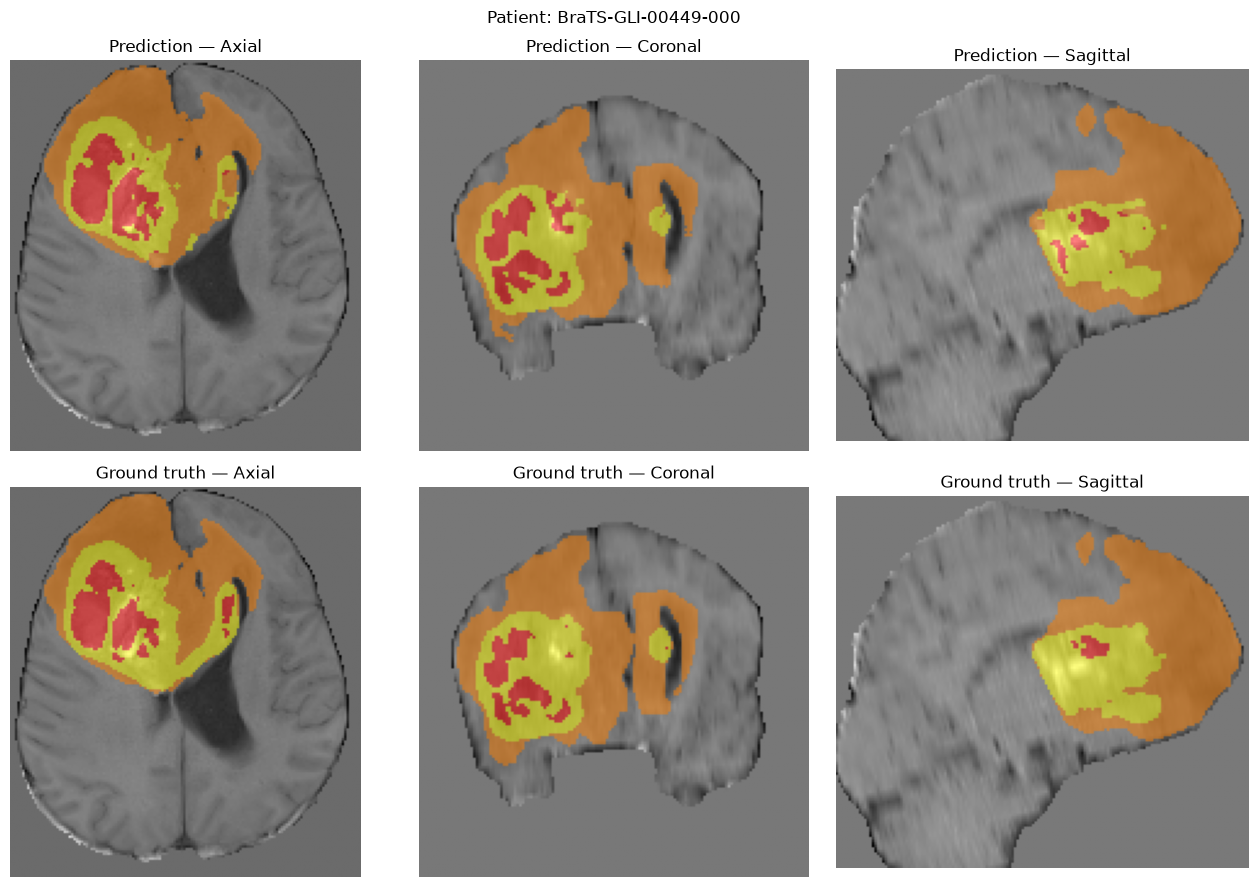

In [14]:
import matplotlib.pyplot as plt

def get_mid_slices_at(volume, center_voxel):
    x, y, z = volume.shape
    cx, cy, cz = [int(round(c)) for c in center_voxel]
    cx, cy, cz = min(max(cx, 0), x - 1), min(max(cy, 0), y - 1), min(max(cz, 0), z - 1)
    return volume[:, :, cz], volume[:, cy, :], volume[cx, :, :]

if prediction_labels is not None and preprocessed_sample is not None:
    base_img = preprocessed_sample["image"][0].numpy()  # first modality channel
    pred_np = prediction_labels.numpy()

    present_regions = [r for r in localization_results if r["present"]]
    if present_regions:
        largest = max(present_regions, key=lambda r: r["voxel_count"])
        center = largest["centroid_voxel"]
    else:
        center = [s / 2 for s in base_img.shape]

    n_rows = 2 if has_ground_truth else 1
    fig, axes = plt.subplots(n_rows, 3, figsize=(13, 4.5 * n_rows))
    if n_rows == 1:
        axes = axes[None, :]

    img_axial, img_coronal, img_sagittal = get_mid_slices_at(base_img, center)
    pred_axial, pred_coronal, pred_sagittal = get_mid_slices_at(pred_np, center)

    for c, (plane_name, base_sl, pred_sl) in enumerate(zip(
            ["Axial", "Coronal", "Sagittal"],
            [img_axial, img_coronal, img_sagittal],
            [pred_axial, pred_coronal, pred_sagittal])):
        axes[0, c].imshow(base_sl.T, cmap="gray", origin="lower")
        masked = np.ma.masked_where(pred_sl.T == 0, pred_sl.T)
        axes[0, c].imshow(masked, cmap="autumn", alpha=0.5, origin="lower")
        axes[0, c].set_title(f"Prediction — {plane_name}")
        axes[0, c].axis("off")

    if has_ground_truth and LABEL_KEY in preprocessed_sample:
        gt_np = preprocessed_sample[LABEL_KEY][0].numpy()
        gt_axial, gt_coronal, gt_sagittal = get_mid_slices_at(gt_np, center)
        for c, (plane_name, base_sl, gt_sl) in enumerate(zip(
                ["Axial", "Coronal", "Sagittal"],
                [img_axial, img_coronal, img_sagittal],
                [gt_axial, gt_coronal, gt_sagittal])):
            axes[1, c].imshow(base_sl.T, cmap="gray", origin="lower")
            masked_gt = np.ma.masked_where(gt_sl.T == 0, gt_sl.T)
            axes[1, c].imshow(masked_gt, cmap="autumn", alpha=0.5, origin="lower")
            axes[1, c].set_title(f"Ground truth — {plane_name}")
            axes[1, c].axis("off")

    fig.suptitle(f"Patient: {target_patient_id}")
    plt.tight_layout()
    plt.show()
else:
    print("No prediction available — skipping visualization.")


## Cell 13 — Save Structured Report

Save localization + volume results as JSON and CSV under `outputs/phase3_reports/`, named per
patient. This is **raw structured data**, not a narrative clinical report (that's a later phase).


In [15]:
import datetime

def save_patient_report(patient_id, localization_results, volume_df, has_ground_truth,
                         sanity_dice, sanity_iou, report_dir):
    report = {
        "patient_id": patient_id,
        "generated_at": datetime.datetime.now().isoformat(timespec="seconds"),
        "ground_truth_available": has_ground_truth,
        "single_patient_sanity_check": {
            "dice": sanity_dice, "iou": sanity_iou,
        } if has_ground_truth else None,
        "localization": localization_results,
        "volumes": volume_df.to_dict(orient="records") if volume_df is not None else None,
        "disclaimer": (
            "Research prototype output. Predictions, localization, and volumes are model-generated "
            "estimates, not clinically validated measurements or diagnoses."
        ),
    }

    json_path = report_dir / f"{patient_id}_phase3_report.json"
    with open(json_path, "w") as f:
        json.dump(report, f, indent=2, default=str)

    csv_path = None
    if volume_df is not None:
        csv_path = report_dir / f"{patient_id}_phase3_volumes.csv"
        volume_df.to_csv(csv_path, index=False)

    print(f"Saved JSON report: {json_path}")
    if csv_path:
        print(f"Saved volume CSV:  {csv_path}")

    return json_path, csv_path

if target_patient_id is not None and localization_results is not None:
    _sanity_dice = single_patient_dice if has_ground_truth and 'single_patient_dice' in dir() else None
    _sanity_iou = single_patient_iou if has_ground_truth and 'single_patient_iou' in dir() else None
    report_json_path, report_csv_path = save_patient_report(
        target_patient_id, localization_results, volume_df, has_ground_truth,
        _sanity_dice, _sanity_iou, REPORT_DIR
    )
else:
    print("Nothing to save — run inference/localization/volume cells above first.")


Saved JSON report: C:\Users\shshi\Downloads\Med_Twin\outputs\phase3_reports\BraTS-GLI-00449-000_phase3_report.json
Saved volume CSV:  C:\Users\shshi\Downloads\Med_Twin\outputs\phase3_reports\BraTS-GLI-00449-000_phase3_volumes.csv


## Cell 14 — Optional: Run Across All Test-Set Patients

Repeats inference + localization + volume measurement for every patient in the Phase 2 **test**
split, producing one summary CSV. This can take a while depending on test-set size and hardware, so
it is gated behind `RUN_BATCH_EVAL` — set explicitly, does not run automatically.


In [18]:
RUN_BATCH_EVAL = True  # set True explicitly to process the full test set

def run_batch_inference(test_patient_ids, dataset_search_root, report_dir):
    summary_rows = []
    for pid in test_patient_ids:
        candidate_dirs = list(dataset_search_root.rglob(pid))
        patient_dir = next((d for d in candidate_dirs if d.is_dir()), None)
        if patient_dir is None:
            print(f"  {pid}: folder not found — skipped")
            continue

        data_dict = find_patient_files(patient_dir, MODALITY_FILENAME_SUFFIXES, LABEL_FILENAME_SUFFIX)
        if any(data_dict.get(k) is None for k in MODALITY_KEYS):
            print(f"  {pid}: missing modality file(s) — skipped")
            continue

        sample = inference_transforms({k: v for k, v in data_dict.items() if v is not None})
        image_batch = sample["image"].unsqueeze(0).to(DEVICE)

        with torch.no_grad():
            logits = sliding_inferer(image_batch, model)
            pred = torch.argmax(torch.softmax(logits, dim=1), dim=1).squeeze(0).cpu()

        affine, axcodes = get_affine_and_orientation(sample)
        loc_results = localize_labels(pred, affine, axcodes, model_bundle["label_mapping"])
        voxel_vol_mm3 = voxel_volume_mm3_from_affine(affine)

        row = {"patient_id": pid}
        for r in loc_results:
            row[f"{r['name']}_volume_cm3"] = round(r["voxel_count"] * voxel_vol_mm3 / 1000.0, 4)
        summary_rows.append(row)
        print(f"  {pid}: done")

    return pd.DataFrame(summary_rows)

if RUN_BATCH_EVAL:
    if model_bundle is None or not model_loaded_ok:
        print("Model not loaded — cannot run batch evaluation.")
    else:
        search_root = OUTPUT_DIR.parent  # search near OUTPUT_DIR for patient folders
        print(f"Running batch inference over {len(model_bundle['split_info']['test_patients'])} "
              f"test patients...")
        batch_summary_df = run_batch_inference(
            model_bundle["split_info"]["test_patients"], search_root, REPORT_DIR
        )
        batch_csv_path = REPORT_DIR / "phase3_test_set_volume_summary.csv"
        batch_summary_df.to_csv(batch_csv_path, index=False)
        print(f"\nSaved batch summary: {batch_csv_path}")
        display(batch_summary_df)
else:
    print("RUN_BATCH_EVAL is False — batch evaluation skipped by design.")
    print("Set RUN_BATCH_EVAL = True and re-run this cell to process the full test set.")


Running batch inference over 188 test patients...
  BraTS-GLI-00449-000: done
  BraTS-GLI-00403-000: done
  BraTS-GLI-00494-000: done
  BraTS-GLI-01029-000: done
  BraTS-GLI-01256-000: done
  BraTS-GLI-01395-000: done
  BraTS-GLI-01438-000: done
  BraTS-GLI-00645-001: done
  BraTS-GLI-00590-000: done
  BraTS-GLI-00105-000: done
  BraTS-GLI-01382-000: done
  BraTS-GLI-01448-000: done
  BraTS-GLI-01095-000: done
  BraTS-GLI-00831-000: done
  BraTS-GLI-01008-000: done
  BraTS-GLI-00298-000: done
  BraTS-GLI-00734-001: done
  BraTS-GLI-00540-001: done
  BraTS-GLI-01003-000: done
  BraTS-GLI-01420-000: done
  BraTS-GLI-00739-000: done
  BraTS-GLI-01237-000: done
  BraTS-GLI-00239-000: done
  BraTS-GLI-01021-000: done
  BraTS-GLI-01442-000: done
  BraTS-GLI-01469-000: done
  BraTS-GLI-01484-000: done
  BraTS-GLI-01499-000: done
  BraTS-GLI-00237-000: done
  BraTS-GLI-00568-000: done
  BraTS-GLI-00746-000: done
  BraTS-GLI-01496-000: done
  BraTS-GLI-01386-000: done
  BraTS-GLI-01282-000: don

,patient_id,necrotic_core_volume_cm3,edema_volume_cm3,enhancing_tumor_volume_cm3
0,BraTS-GLI-00449-000,23.619,152.501,50.817
1,BraTS-GLI-00403-000,4.469,21.777,12.299
2,BraTS-GLI-00494-000,21.840,51.387,21.295
3,BraTS-GLI-01029-000,2.837,128.826,20.861
4,BraTS-GLI-01256-000,42.288,63.475,31.688
...,...,...,...,...
183,BraTS-GLI-01117-000,4.429,3.940,22.835
184,BraTS-GLI-01657-000,0.996,120.168,12.752
185,BraTS-GLI-01509-000,0.083,25.514,0.000
186,BraTS-GLI-01304-000,10.676,75.434,13.804


## Cell 15 — Final Summary and Next Phase


In [17]:
def print_phase3_summary():
    print("=" * 60)
    print("PHASE 3 — LOCALIZATION & VOLUMETRY READINESS REPORT")
    print("=" * 60)

    checks = {
        "Model bundle loaded": model_bundle is not None,
        "Model weights loaded": model_loaded_ok,
        "Input patient located": patient_data_dict is not None,
        "Inference produced a prediction": prediction_labels is not None,
        "Localization computed": localization_results is not None,
        "Volumes computed": volume_df is not None,
    }
    for name, passed in checks.items():
        print(f"  [{'PASS' if passed else 'FAIL'}] {name}")

    print(f"\nPatient:              {target_patient_id}")
    print(f"Inference mode:        {INFERENCE_MODE}")
    print(f"Ground truth used:     {has_ground_truth}")

    if volume_df is not None:
        print("\nVolume summary:")
        for _, row in volume_df.iterrows():
            print(f"  {row['region']:<30} {row['volume_cm3']:.3f} cm^3")

    all_passed = all(checks.values())
    print()
    if all_passed:
        print("PHASE 3 LOCALIZATION & VOLUMETRY READY")
    else:
        print("Pipeline is NOT fully ready — resolve the FAILed checks above.")

    print(
        "\nReminder: this is a research prototype. Predictions, localization, and volumes are "
        "model-generated estimates, not clinically validated measurements or diagnoses."
    )

    print("\n" + "-" * 60)
    print("Next Phase (not implemented here):")
    print("  3D Tumor Mesh Reconstruction & Interactive Viewer")
    print("  Recommended: convert the predicted label volume into a 3D surface mesh")
    print("  (e.g. marching cubes) and render it interactively, using this phase's")
    print("  segmentation + volume outputs as input.")

print_phase3_summary()


PHASE 3 — LOCALIZATION & VOLUMETRY READINESS REPORT
  [PASS] Model bundle loaded
  [PASS] Model weights loaded
  [PASS] Input patient located
  [PASS] Inference produced a prediction
  [PASS] Localization computed
  [PASS] Volumes computed

Patient:              BraTS-GLI-00449-000
Inference mode:        test_patient
Ground truth used:     True

Volume summary:
  necrotic_core                  23.619 cm^3
  edema                          152.501 cm^3
  enhancing_tumor                50.817 cm^3
  whole_tumor (composite)        226.937 cm^3
  tumor_core (composite)         74.436 cm^3
  enhancing_tumor_only (composite) 50.817 cm^3

PHASE 3 LOCALIZATION & VOLUMETRY READY

Reminder: this is a research prototype. Predictions, localization, and volumes are model-generated estimates, not clinically validated measurements or diagnoses.

------------------------------------------------------------
Next Phase (not implemented here):
  3D Tumor Mesh Reconstruction & Interactive Viewer
  Recommen